In [1]:
import os
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# Define the base directories
data_dir = Path(r"/kaggle/input/power-system/segmentation_data/fllanza_data")
labels_dir = Path(r"/kaggle/input/power-system/segmentation_labels/segmentation_labels")

# Function to load labels into a separate dataframe
def load_labels(label_file):
    labels_df = pd.read_csv(labels_dir / label_file)
    labels_df_cleaned = labels_df.dropna().copy()  # Ensure it's a copy
    labels_df_cleaned["sample_id"] = labels_df_cleaned["sample_id"].astype(int)
    return labels_df_cleaned  # Return the cleaned labels DataFrame

# Function to load measurement data into a separate dataframe
def load_measurements(segment_folder):
    combined_data = []

    # Loop through all sample folders
    for sample_folder in data_dir.iterdir():
        if sample_folder.is_dir():
            sample_id = sample_folder.name  # Extract sample ID from folder name
            measurement_file = sample_folder / segment_folder / "measurements.csv"
            
            if measurement_file.exists():
                df = pd.read_csv(measurement_file)
                df["Time"] = pd.to_numeric(df["Time"])  # Ensure 'Time' column is numeric
                df["sample_id"] = int(sample_id)  # Store sample_id
                combined_data.append(df)
            else:
                print(f"Measurements file not found for Sample ID {sample_id} in {segment_folder}.")

    # Concatenate all data
    if combined_data:
        measurements_df = pd.concat(combined_data, ignore_index=True)
        measurements_df["sample_id"] = measurements_df["sample_id"].astype(int)
        return measurements_df
    else:
        return pd.DataFrame()

# Load J03 and J04 labels
labels_J03 = load_labels("J03_labels.csv")
labels_J04 = load_labels("J04_labels.csv")

# Load J03 and J04 measurement data
measurements_J03 = load_measurements("J03")
measurements_J04 = load_measurements("J04")

# Display both separate dataframes
print("Labels DataFrame:")
print(labels_J03.head())

print("\nMeasurements DataFrame:")
print(measurements_J03.head())

# Sort by 'sample_id' first, then by 'Time' within each sample_id
measurements_J03 = measurements_J03.sort_values(by=["sample_id", "Time"]).reset_index(drop=True)
# Sort by 'sample_id' first, then by 'Time' within each sample_id
measurements_J04 = measurements_J04.sort_values(by=["sample_id", "Time"]).reset_index(drop=True)

Measurements file not found for Sample ID 3531 in J03.
Measurements file not found for Sample ID 15244 in J03.
Measurements file not found for Sample ID 8676 in J03.
Measurements file not found for Sample ID 26404 in J03.
Measurements file not found for Sample ID 7310 in J03.
Measurements file not found for Sample ID 8715 in J03.
Measurements file not found for Sample ID 6025 in J03.
Measurements file not found for Sample ID 30786 in J03.
Measurements file not found for Sample ID 4371 in J03.
Measurements file not found for Sample ID 27134 in J03.
Measurements file not found for Sample ID 22706 in J03.
Measurements file not found for Sample ID 17184 in J03.
Measurements file not found for Sample ID 3562 in J03.
Measurements file not found for Sample ID 11496 in J03.
Measurements file not found for Sample ID 20826 in J03.
Measurements file not found for Sample ID 22999 in J03.
Measurements file not found for Sample ID 8912 in J03.
Measurements file not found for Sample ID 8685 in J03.
M

In [2]:
from sklearn.preprocessing import RobustScaler
# Define phase columns
voltage_columns = ["U1", "U2", "U3"]
current_columns = ["I1", "I2", "I3"]

# Create a RobustScaler instance
scaler = RobustScaler()

# Normalize voltage and current columns before RMS calculation
measurements_J03[voltage_columns] = scaler.fit_transform(measurements_J03[voltage_columns])
# measurements_J03[current_columns] = scaler.fit_transform(measurements_J03[current_columns])

# Normalize voltage and current columns before RMS calculation
measurements_J04[voltage_columns] = scaler.fit_transform(measurements_J04[voltage_columns])
# measurements_J04[current_columns] = scaler.fit_transform(measurements_J04[current_columns])

In [3]:
def normalize_using_first_two_cycles_amplitude(df, columns):
    """
    Normalize each sample using the amplitude (max - min) of the first two cycles (0.04s).
    """
    normalized_df = df.copy()

    for sample_id in df["sample_id"].unique():
        sample_df = df[df["sample_id"] == sample_id].copy()

        # Define the first two cycles as the first 0.04 seconds
        start_time = sample_df["Time"].min()
        time_threshold = start_time + 0.04
        first_two_cycles = sample_df[sample_df["Time"] <= time_threshold]

        if not first_two_cycles.empty:
            # Compute amplitude (max - min) for each column
            amplitude = first_two_cycles[columns].max() - first_two_cycles[columns].min()

            # Avoid division by zero (if amplitude is 0, set to 1)
            amplitude.replace(0, 1, inplace=True)

            # Normalize the entire sample
            normalized_df.loc[df["sample_id"] == sample_id, columns] = sample_df[columns] / amplitude

    return normalized_df

# Apply normalization to current signals
measurements_J03 = normalize_using_first_two_cycles_amplitude(measurements_J03, current_columns)
measurements_J04 = normalize_using_first_two_cycles_amplitude(measurements_J04, current_columns)

In [4]:
import numpy as np
import pandas as pd

# Function to calculate RMS for each segment (40 samples)
def calculate_rms_by_segments(df, voltage_columns, current_columns, segment_size=40):
    rms_values = []

    # Iterate through unique sample IDs
    for sample_id in df["sample_id"].unique():
        sample_data = df[df["sample_id"] == sample_id].reset_index(drop=True)

        num_samples = len(sample_data)

        # Segment the data in chunks of 'segment_size'
        for start_idx in range(1, num_samples, segment_size):
            end_idx = min(start_idx + segment_size, num_samples)
            segment_df = sample_data.iloc[start_idx:end_idx]

            # Compute RMS for this segment
            rms_segment = {"sample_id": sample_id, "Segment": start_idx // segment_size + 1}

            for phase in voltage_columns:
                rms_segment[f"RMS_{phase}"] = np.sqrt(np.mean(segment_df[phase] ** 2))

            for phase in current_columns:
                rms_segment[f"RMS_{phase}"] = np.sqrt(np.mean(segment_df[phase] ** 2))

            # Store the end time of the segment
            rms_segment["Time"] = segment_df.iloc[-1]["Time"]

            rms_values.append(rms_segment)

    return pd.DataFrame(rms_values)



# Calculate RMS on the filtered signals
rms_df = calculate_rms_by_segments(measurements_J03, voltage_columns, current_columns)
rms_df2 = calculate_rms_by_segments(measurements_J04, voltage_columns, current_columns)

# Sort and reset index
rms_df = rms_df.sort_values(by=["sample_id", "Time"]).reset_index(drop=True)
rms_df2 = rms_df2.sort_values(by=["sample_id", "Time"]).reset_index(drop=True)

In [5]:
def compute_derivative(rms_df, voltage_columns, current_columns):
    new_df = rms_df.copy()  # Create a copy to avoid chained assignment issues
    
    # Process each unique sample_id separately
    for sample_id in new_df["sample_id"].unique():
        # Get data for this sample_id
        sample_mask = new_df["sample_id"] == sample_id
        sample_data = new_df[sample_mask]
        
        # Get indices for this sample in the original dataframe
        sample_indices = sample_data.index
        
        for phase in voltage_columns + current_columns:
            rms_col = f"RMS_{phase}"
            dy_dx_col = f"d_{phase}/dt"   # First derivative
            d2y_dx2_col = f"d2_{phase}/dt2"  # Second derivative
            
            # Compute derivatives only for this sample
            dy_dx_values = np.gradient(sample_data[rms_col], sample_data["Time"])
            d2y_dx2_values = np.gradient(dy_dx_values, sample_data["Time"])
            
            # Assign computed values back to the original dataframe at the correct indices
            new_df.loc[sample_indices, dy_dx_col] = dy_dx_values
            new_df.loc[sample_indices, d2y_dx2_col] = d2y_dx2_values
    
    return new_df  # Return the updated DataFrame

# Apply derivative computation to both datasets
rms_df = compute_derivative(rms_df, voltage_columns, current_columns)
rms_df2 = compute_derivative(rms_df2, voltage_columns, current_columns)

In [6]:
import numpy as np
import pandas as pd

def normalize_derivatives(df, voltage_columns, current_columns, method='z-score'):
    """
    Normalize the derivatives using different methods
    
    Parameters:
    -----------
    df : pandas.DataFrame
        Input dataframe with derivatives
    voltage_columns : list
        List of voltage column names
    current_columns : list
        List of current column names
    method : str, optional (default='z-score')
        Normalization method to use. Options:
        - 'z-score': Standard scaling (zero mean, unit variance)
        - 'min-max': Scale to [0, 1] range
        - 'robust': Scaling using median and interquartile range
    
    Returns:
    --------
    pandas.DataFrame
        Dataframe with normalized derivatives
    """
    new_df = df.copy()
    
    # Columns to normalize
    derivative_columns = []
    for phase in voltage_columns + current_columns:
        derivative_columns.extend([f"d_{phase}/dt", f"d2_{phase}/dt2"])
    
    if method == 'z-score':
        # Z-score normalization (standard scaling)
        for col in derivative_columns:
            new_df[f'norm_{col}'] = (new_df[col] - new_df[col].mean()) / new_df[col].std()
    
    elif method == 'min-max':
        # Min-Max scaling to [0, 1] range
        for col in derivative_columns:
            min_val = new_df[col].min()
            max_val = new_df[col].max()
            new_df[f'norm_{col}'] = (new_df[col] - min_val) / (max_val - min_val)
    
    elif method == 'robust':
        # Robust scaling using median and interquartile range
        for col in derivative_columns:
            median = new_df[col].median()
            iqr = new_df[col].quantile(0.75) - new_df[col].quantile(0.25)
            new_df[f'norm_{col}'] = (new_df[col] - median) / iqr
    
    else:
        raise ValueError("Invalid normalization method. Choose 'z-score', 'min-max', or 'robust'.")
    
    return new_df

# Example usage
# Assuming rms_df and rms_df2 are your dataframes
rms_df = normalize_derivatives(rms_df, voltage_columns, current_columns, method='min-max')
rms_df2= normalize_derivatives(rms_df2, voltage_columns, current_columns, method='min-max')

In [7]:
rms_df.head()

,sample_id,Segment,RMS_U1,RMS_U2,RMS_U3,RMS_I1,RMS_I2,RMS_I3,Time,d_U1/dt,...,norm_d_U2/dt,norm_d2_U2/dt2,norm_d_U3/dt,norm_d2_U3/dt2,norm_d_I1/dt,norm_d2_I1/dt2,norm_d_I2/dt,norm_d2_I2/dt2,norm_d_I3/dt,norm_d2_I3/dt2
0,14,1,0.327783,0.335860,0.335925,0.348703,0.332570,0.346571,0.01,-0.200626,...,0.433286,0.414785,0.890915,0.913183,0.411114,0.565879,0.356743,0.608518,0.513882,0.585541
1,14,2,0.325777,0.332781,0.334908,0.339100,0.341626,0.349580,0.02,-0.016404,...,0.434436,0.414126,0.891157,0.913039,0.411124,0.565872,0.356735,0.608522,0.513878,0.585545
2,14,3,0.327455,0.335865,0.335798,0.349631,0.332011,0.345714,0.03,0.016193,...,0.434404,0.413506,0.891137,0.912931,0.411124,0.565866,0.356734,0.608528,0.513879,0.585550
3,14,4,0.326100,0.332614,0.334620,0.340232,0.338336,0.350391,0.04,0.007174,...,0.434440,0.413532,0.891182,0.912957,0.411124,0.565865,0.356736,0.608529,0.513881,0.585548
4,14,5,0.327598,0.335892,0.335870,0.351704,0.333375,0.349753,0.05,-0.008041,...,0.434455,0.413515,0.891210,0.912897,0.411123,0.565864,0.356736,0.608527,0.513880,0.585544


In [8]:
import numpy as np
import pandas as pd

# Function to create labels dynamically according to rms_df
def create_dynamic_labels(rms_df, labels_df):
    # Initialize empty lists to store start_t and end_t for each row
    start_times = []
    end_times = []

    # Iterate through each sample_id in the rms_df
    for sample_id in rms_df["sample_id"].unique():
        # Get all labels for the current sample_id
        sample_labels = labels_df[labels_df["sample_id"] == sample_id]

        # Get the time intervals for the sample_id
        sample_times = sample_labels[['start_t', 'end_t']].values

        # Sort the time intervals in case they are not in order
        sample_times = sorted(sample_times, key=lambda x: x[0])

        # Get the rows in rms_df corresponding to this sample_id
        sample_rms = rms_df[rms_df["sample_id"] == sample_id].reset_index(drop=True)

        # Iterate through the rows of sample_rms and assign the correct start_t and end_t
        label_idx = 0
        for idx, row in sample_rms.iterrows():
            # Assign the current start_t and end_t to this row
            start_times.append(sample_times[label_idx][0])
            end_times.append(sample_times[label_idx][1])

            # Check if we need to switch to the next label (after the end_t time is passed)
            if row["Time"] > sample_times[label_idx][1]:
                # Switch to the next label if available
                if label_idx + 1 < len(sample_times):
                    label_idx += 1

    # Add the start and end times as new columns to the rms_df
    rms_df["start_t"] = start_times
    rms_df["end_t"] = end_times

    return rms_df


# Example Usage:
# Create the dynamic labels for rms_df based on the labels in labels_J03
rms_df_with_labels = create_dynamic_labels(rms_df, labels_J03)
rms_df_with_labels2 = create_dynamic_labels(rms_df2, labels_J04)

# Display the first few rows with the new labels
print(rms_df_with_labels.head())

   sample_id  Segment    RMS_U1    RMS_U2    RMS_U3    RMS_I1    RMS_I2  \
0         14        1  0.327783  0.335860  0.335925  0.348703  0.332570   
1         14        2  0.325777  0.332781  0.334908  0.339100  0.341626   
2         14        3  0.327455  0.335865  0.335798  0.349631  0.332011   
3         14        4  0.326100  0.332614  0.334620  0.340232  0.338336   
4         14        5  0.327598  0.335892  0.335870  0.351704  0.333375   

     RMS_I3  Time   d_U1/dt  ...  norm_d_U3/dt  norm_d2_U3/dt2  norm_d_I1/dt  \
0  0.346571  0.01 -0.200626  ...      0.890915        0.913183      0.411114   
1  0.349580  0.02 -0.016404  ...      0.891157        0.913039      0.411124   
2  0.345714  0.03  0.016193  ...      0.891137        0.912931      0.411124   
3  0.350391  0.04  0.007174  ...      0.891182        0.912957      0.411124   
4  0.349753  0.05 -0.008041  ...      0.891210        0.912897      0.411123   

   norm_d2_I1/dt2  norm_d_I2/dt  norm_d2_I2/dt2  norm_d_I3/dt  norm_

In [9]:
rms_df_with_labels[rms_df_with_labels["sample_id"] == 924]

,sample_id,Segment,RMS_U1,RMS_U2,RMS_U3,RMS_I1,RMS_I2,RMS_I3,Time,d_U1/dt,...,norm_d_U3/dt,norm_d2_U3/dt2,norm_d_I1/dt,norm_d2_I1/dt2,norm_d_I2/dt,norm_d2_I2/dt2,norm_d_I3/dt,norm_d2_I3/dt2,start_t,end_t
3000,924,1,0.319488,0.332944,0.330359,0.338295,0.334331,0.350414,0.01000,0.251632,...,0.890242,0.913956,0.411130,0.565858,0.356740,0.608523,0.513870,0.585563,0.493674,0.822858
3001,924,2,0.322005,0.333369,0.326689,0.345211,0.340557,0.343125,0.02000,-0.005544,...,0.891185,0.913474,0.411125,0.565861,0.356737,0.608524,0.513880,0.585555,0.493674,0.822858
3002,924,3,0.319378,0.332665,0.330453,0.341105,0.337369,0.352460,0.03000,-0.001389,...,0.891253,0.912920,0.411124,0.565864,0.356734,0.608527,0.513879,0.585546,0.493674,0.822858
3003,924,4,0.321977,0.333211,0.327317,0.346362,0.336482,0.343960,0.04000,-0.002965,...,0.891192,0.912851,0.411122,0.565865,0.356735,0.608530,0.513878,0.585547,0.493674,0.822858
3004,924,5,0.319318,0.332539,0.330602,0.338300,0.336966,0.351829,0.05000,0.006833,...,0.891134,0.912902,0.411124,0.565867,0.356738,0.608528,0.513878,0.585548,0.493674,0.822858
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3146,924,147,0.319372,0.333029,0.331652,0.344962,0.333186,0.354665,1.47000,0.012124,...,0.891097,0.912911,0.411124,0.565867,0.356735,0.608530,0.513878,0.585547,0.993885,1.365917
3147,924,148,0.321177,0.332298,0.328616,0.348988,0.346145,0.341913,1.48000,-0.002415,...,0.891140,0.912947,0.411125,0.565865,0.356736,0.608528,0.513879,0.585547,0.993885,1.365917
3148,924,149,0.319324,0.333166,0.331389,0.347399,0.335853,0.355330,1.49000,0.008188,...,0.891152,0.456093,0.411123,0.567160,0.356735,0.608120,0.513877,0.584175,0.993885,1.365917
3149,924,150,0.321341,0.332484,0.328451,0.347338,0.346642,0.339594,1.50000,31.199239,...,0.062123,0.000000,0.412880,0.568455,0.356067,0.607705,0.512177,0.582831,0.993885,1.365917


In [10]:
# Count the number of rows per sample_id
sample_sizes = rms_df_with_labels.groupby('sample_id').size()

# Filter out sample_ids with more than 100 rows
samples_to_keep = sample_sizes[sample_sizes <= 100].index

# Filter the original DataFrame to keep only these samples
rms_df_filtered = rms_df_with_labels[rms_df_with_labels['sample_id'].isin(samples_to_keep)]



# Count the number of rows per sample_id
sample_sizes = rms_df_with_labels2.groupby('sample_id').size()

# Filter out sample_ids with more than 100 rows
samples_to_keep = sample_sizes[sample_sizes <= 100].index

# Filter the original DataFrame to keep only these samples
rms_df_filtered2 = rms_df_with_labels2[rms_df_with_labels2['sample_id'].isin(samples_to_keep)]

In [11]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# Define all features including RMS, derivatives, and rolling variance
features = [
    # Original RMS features
    'RMS_U1', 'RMS_U2', 'RMS_U3', 'RMS_I1', 'RMS_I2', 'RMS_I3',
    
    # First derivatives
    'd_U1/dt', 'd_U2/dt', 'd_U3/dt', 'd_I1/dt', 'd_I2/dt', 'd_I3/dt'
    
]

print(features)

# Define the labels (target data)
labels = ['start_t', 'end_t']

# Select the features and labels from the merged dataframe
X1 = rms_df_filtered[features].values
y1 = rms_df_filtered[labels].values
time_values1 = rms_df_filtered['Time'].values

X2 = rms_df_filtered2[features].values
y2 = rms_df_filtered2[labels].values
time_values2 = rms_df_filtered2['Time'].values

['RMS_U1', 'RMS_U2', 'RMS_U3', 'RMS_I1', 'RMS_I2', 'RMS_I3', 'd_U1/dt', 'd_U2/dt', 'd_U3/dt', 'd_I1/dt', 'd_I2/dt', 'd_I3/dt']


In [12]:
import numpy as np
from sklearn.model_selection import train_test_split


# Assuming X1 and X2 are already defined, you can scale both sets
X_scaled1 = X1
X_scaled2 = X2

# Step 1: Create Sequences and Track Indices
def create_sequences_with_indices(X, y, time, time_steps=50):
    X_seq, y_seq, time_seq, indices = [], [], [], []
    for i in range(0,len(X) - time_steps,time_steps):
        X_seq.append(X[i:i + time_steps])
        y_seq.append(y[i + time_steps-1])
        time_seq.append(time[i + time_steps])
        indices.append(i)  # Store the original index
    return np.array(X_seq), np.array(y_seq), np.array(time_seq), np.array(indices)

In [13]:
from sklearn.model_selection import train_test_split

# Define test size
test_size = 2500  # Last 2500 samples from each dataset

# Split X1 and X2 separately
X_train1, X_test1 = X_scaled1[:-test_size], X_scaled1[-test_size:]
y_train1, y_test1 = y1[:-test_size], y1[-test_size:]
time_train1, time_test1 = time_values1[:-test_size], time_values1[-test_size:]

X_train2, X_test2 = X_scaled2[:-test_size], X_scaled2[-test_size:]
y_train2, y_test2 = y2[:-test_size], y2[-test_size:]
time_train2, time_test2 = time_values2[:-test_size], time_values2[-test_size:]

# Concatenate the training data
X_train = np.concatenate([X_train1, X_train2], axis=0)
y_train = np.concatenate([y_train1, y_train2], axis=0)
time_train = np.concatenate([time_train1, time_train2], axis=0)

# Concatenate the test data
X_test = np.concatenate([X_test1, X_test2], axis=0)
y_test = np.concatenate([y_test1, y_test2], axis=0)
time_test = np.concatenate([time_test1, time_test2], axis=0)

# ✅ NEW: Split Train Data into Train and Validation (80% train, 20% validation)
X_train_final, X_val, y_train_final, y_val, time_train_final, time_val = train_test_split(
    X_train, y_train, time_train, test_size=2500, random_state=42, shuffle = False
)

# Apply Windowing to Training and Validation Data
X_train_seq, y_train_seq, time_train_seq, _ = create_sequences_with_indices(X_train_final, y_train_final, time_train_final, time_steps=100)

In [14]:
# Extract unique sample IDs for test data from each dataset separately
sample_ids_test1 = rms_df_filtered['sample_id'].iloc[-test_size:].unique()
sample_ids_test2 = rms_df_filtered2['sample_id'].iloc[-test_size:].unique()

# Concatenate the unique sample IDs while keeping duplicates from both datasets
final_sample_ids = np.concatenate([sample_ids_test1, sample_ids_test2])

# Optionally save to a file
np.savetxt("final_test_sample_ids_100.csv", final_sample_ids, delimiter=",", fmt="%s")

# Display first few sample IDs
print(len(final_sample_ids))  # Just to verify


50


In [15]:
def create_sequences_with_indices_val(X, y, time, time_steps=50):
    X_seq, y_seq, time_seq = [], [], []
    
    # Iterate over the test data, creating windows of 100 time steps
    for i in range(0,(len(X) - time_steps)+time_steps, time_steps):  # Ensure the windows fit in the available data
        X_seq.append(X[i:i + time_steps])  # Create the window of features
        y_seq.append(y[i + time_steps-1])  # Assign the last label for the window
        time_seq.append(time[i:i + time_steps])  # Use the time associated with the last label
    
    return np.array(X_seq), np.array(y_seq), np.array(time_seq)

X_val_seq, y_val_seq, time_val_seq = create_sequences_with_indices_val(X_val, y_val, time_val, time_steps=100)

In [16]:
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)  # If using CUDA

def create_windows_for_test(X, y, time, time_steps=50):
    X_seq, y_seq, time_seq = [], [], []
    
    # Iterate over the test data, creating windows of 100 time steps
    for i in range(0,(len(X) - time_steps)+time_steps, time_steps):  # Ensure the windows fit in the available data
        X_seq.append(X[i:i + time_steps])  # Create the window of features
        y_seq.append(y[i + 1])  # Assign the last label for the window
        time_seq.append(time[i:i + time_steps])  # Use the time associated with the last label
    
    return np.array(X_seq), np.array(y_seq), np.array(time_seq)

# Apply the function to the test data
X_test_seq, y_test_seq, time_test_seq = create_windows_for_test(X_test, y_test, time_test, time_steps=100)

In [17]:
def iou_loss(pred, target):
    pred_start, pred_end = pred[:, 0], pred[:, 1]
    true_start, true_end = target[:, 0], target[:, 1]

    intersection = torch.clamp(torch.min(pred_end, true_end) - torch.max(pred_start, true_start), min=0)
    union = (true_end - true_start) + (pred_end - pred_start) - intersection

    iou = intersection / (union + 1e-6)  # Avoid division by zero
    return torch.mean(1 - iou)  # IoU loss to be minimized

def combined_loss(pred, target, alpha=0.5):
    """
    Combined loss function: (alpha * Smooth L1 Loss) + ((1-alpha) * IoU Loss)
    - `alpha`: Weight to balance the two losses.
    - Recommended `alpha = 0.5` for equal weight.
    """
    l1_loss = nn.SmoothL1Loss()(pred, target)
    iou_loss_value = iou_loss(pred, target)
    return alpha * l1_loss + (1 - alpha) * iou_loss_value


In [18]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim


torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

X_train_tensor = torch.tensor(X_train_seq, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_seq, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_seq, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_seq, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_seq, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_seq, dtype=torch.float32)


# Move tensors to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_train_tensor, y_train_tensor = X_train_tensor.to(device), y_train_tensor.to(device)
X_val_tensor, y_val_tensor = X_val_tensor.to(device), y_val_tensor.to(device)
X_test_tensor, y_test_tensor = X_test_tensor.to(device), y_test_tensor.to(device)
     

# import torch
# import torch.nn as nn
# import torch.optim as optim
# import torch.nn.functional as F


# class CNN_GRU_Attention(nn.Module):
#     def __init__(self, input_dim, hidden_dim, num_layers, output_dim=2):
#         super(CNN_GRU_Attention, self).__init__()
        
#         # CNN Feature Extractor
#         self.conv1 = nn.Conv1d(in_channels=input_dim, out_channels=32, kernel_size=3)
#         self.conv2 = nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3) 
#         self.conv3 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3)
#         self.pool = nn.MaxPool1d(kernel_size=2)
        
#         # GRU
#         self.gru = nn.GRU(input_size=128, hidden_size=hidden_dim, num_layers=num_layers, 
#                           batch_first=True, bidirectional=True)

#         # Attention mechanism
#         self.attention = nn.Linear(hidden_dim * 2, 1)  # 2 for bidirectional GRU
#         self.softmax = nn.Softmax(dim=1)
        
#         # Fully Connected Layer
#         self.fc = nn.Linear(hidden_dim * 2, output_dim)  # Using attention-weighted context

#     def forward(self, x):
#         # CNN Feature Extraction
#         x = x.permute(0, 2, 1)  # Change to (batch, channels, time) for CNN
#         x = self.pool(F.relu(self.conv1(x)))
#         x = self.pool(F.relu(self.conv2(x)))
#         x = self.pool(F.relu(self.conv3(x)))
        
#         # Reshape for GRU
#         x = x.permute(0, 2, 1)  # Change back to (batch, time, features) for GRU
#         gru_out, _ = self.gru(x)  # Shape: (batch, time_steps, hidden_dim*2)

#         # Attention Mechanism
#         attention_scores = self.attention(gru_out)  # Shape: (batch, time_steps, 1)
#         attention_weights = self.softmax(attention_scores)  # Shape: (batch, time_steps, 1)
        
#         # Apply attention weights
#         context_vector = torch.sum(gru_out * attention_weights, dim=1)  # Shape: (batch, hidden_dim*2)

#         # Fully Connected Layer
#         output = self.fc(context_vector)  # Output shape: (batch, output_dim)
        
#         return output


# # Model Initialization
# input_dim = X_train_tensor.shape[2]  # Number of features
# hidden_dim = 128
# num_layers = 3
# output_dim = 2  # Output is (start_time, end_time)

# model = CNN_GRU_Attention(input_dim, hidden_dim, num_layers).to(device)

In [19]:
from torch.utils.data import DataLoader, TensorDataset

# Define batch size (using the best-tuned value)
batch_size = 16  # Make sure this matches the best batch size

# Create DataLoader for training
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Create DataLoader for validation
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# Create DataLoader for testing (optional)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


In [20]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Set PyTorch to deterministic mode for reproducibility
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Move tensors to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_train_tensor = torch.tensor(X_train_seq, dtype=torch.float32).to(device)
y_train_tensor = torch.tensor(y_train_seq, dtype=torch.float32).to(device)
X_val_tensor = torch.tensor(X_val_seq, dtype=torch.float32).to(device)
y_val_tensor = torch.tensor(y_val_seq, dtype=torch.float32).to(device)
X_test_tensor = torch.tensor(X_test_seq, dtype=torch.float32).to(device)
y_test_tensor = torch.tensor(y_test_seq, dtype=torch.float32).to(device)

# Temporal Fast R-CNN Model
class TemporalFastRCNN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim=2):
        super(TemporalFastRCNN, self).__init__()
        
        # Feature extraction backbone (1D CNN)
        self.backbone = nn.Sequential(
            nn.Conv1d(in_channels=input_dim, out_channels=32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        
        # Region Proposal Network (RPN)
        self.rpn_conv = nn.Conv1d(128, 128, kernel_size=3, padding=1)
        self.rpn_cls = nn.Conv1d(128, 2, kernel_size=1)  # 2 classes (foreground/background)
        self.rpn_reg = nn.Conv1d(128, 2, kernel_size=1)  # 2 values (start, end offsets)
        
        # RoI Pooling and Classifier
        self.roi_pool_size = 7
        
        # After RoI pooling, we have fixed-length feature vectors
        self.fc1 = nn.Linear(128 * self.roi_pool_size, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)
        
        # Final prediction layers
        self.bbox_pred = nn.Linear(hidden_dim, output_dim)  # Regression for start and end time
        
        # Dropout for regularization
        self.dropout = nn.Dropout(0.1)
        
    def forward(self, x):
        batch_size = x.size(0)
        
        # CNN Feature Extraction (with permute for 1D conv)
        x = x.permute(0, 2, 1)  # (batch_size, features, sequence_length)
        features = self.backbone(x)
        
        # Region Proposal Network
        rpn_features = F.relu(self.rpn_conv(features))
        rpn_cls_scores = self.rpn_cls(rpn_features)
        rpn_bbox_preds = self.rpn_reg(rpn_features)
        
        # Simulate RoI pooling - in a complete implementation, this would use proposals
        # Here we simplify by using adaptive pooling on the entire feature map
        pooled_features = F.adaptive_max_pool1d(features, self.roi_pool_size)
        pooled_features = pooled_features.view(batch_size, -1)
        
        # Fully connected layers with dropout
        fc1_out = F.relu(self.fc1(pooled_features))
        fc1_out = self.dropout(fc1_out)
        fc2_out = F.relu(self.fc2(fc1_out))
        fc2_out = self.dropout(fc2_out)
        
        # Final boundary predictions (start, end)
        bbox_preds = self.bbox_pred(fc2_out)
        
        return bbox_preds

# IoU loss function for training
def iou_loss(pred, target):
    # Extract start and end times
    pred_start, pred_end = pred[:, 0], pred[:, 1]
    target_start, target_end = target[:, 0], target[:, 1]
    
    # Calculate intersection
    intersection_start = torch.max(pred_start, target_start)
    intersection_end = torch.min(pred_end, target_end)
    intersection = torch.clamp(intersection_end - intersection_start, min=0)
    
    # Calculate union
    pred_length = pred_end - pred_start
    target_length = target_end - target_start
    union = pred_length + target_length - intersection
    
    # IoU loss (1 - IoU)
    iou = intersection / (union + 1e-7)
    return 1 - torch.mean(iou)

# Combined loss function (MSE + IoU loss)
def combined_loss(pred, target):
    mse_loss = F.mse_loss(pred, target)
    iou = iou_loss(pred, target)
    return mse_loss + iou

# Model Initialization
input_dim = X_train_tensor.shape[2]  # Number of features
hidden_dim = 64  # Increased hidden dimension for more capacity
output_dim = 2  # Output is (start_time, end_time)
model = TemporalFastRCNN(input_dim, hidden_dim, output_dim).to(device)

# Create DataLoaders
batch_size = 16
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Optimizer with weight decay for regularization
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

# Learning rate scheduler with warmup
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.7, patience=5, verbose=True)

# Training Loop
num_epochs = 100
best_val_loss = float("inf")
best_model_path = "best_fast_rcnn_model.pth"
patience = 15  # Increased patience for more training time
no_improve_count = 0

# Store history for visualization
train_losses = []
val_losses = []
val_ious = []

for epoch in range(num_epochs):
    # Training Phase
    model.train()
    train_loss = 0.0
    
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        y_pred = model(X_batch)
        loss = combined_loss(y_pred, y_batch)
        loss.backward()
        # Gradient clipping to prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        
        train_loss += loss.item()
    
    train_loss /= len(train_loader)
    train_losses.append(train_loss)
    
    # Validation Phase
    model.eval()
    val_loss = 0.0
    val_iou = 0.0
    
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = combined_loss(y_pred, y_batch)
            val_loss += loss.item()
            
            # Compute IoU for each batch
            batch_iou = 1 - iou_loss(y_pred, y_batch).item()
            val_iou += batch_iou
    
    val_loss /= len(val_loader)
    val_iou /= len(val_loader)
    val_losses.append(val_loss)
    val_ious.append(val_iou)
    
    # Update learning rate
    scheduler.step(val_loss)
    
    # Track best validation IoU
    best_val_iou = val_ious[0] if epoch == 0 else max(max(val_ious), val_iou)
    
    # Early stopping check
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch_iou = val_iou
        torch.save(model.state_dict(), best_model_path)
        no_improve_count = 0
    else:
        no_improve_count += 1
    
    if no_improve_count >= patience:
        print("Early stopping triggered.")
        break
    
    print(f"Epoch [{epoch+1}/{num_epochs}] - Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val IoU: {val_iou:.4f}")

print(f"Best validation loss: {best_val_loss:.4f}, Best validation IoU: {best_epoch_iou:.4f}, Model saved to {best_model_path}")

# Load best model and evaluate on test set
model.load_state_dict(torch.load(best_model_path))
model.eval()

with torch.no_grad():
    y_pred_list = []
    for i in range(0, len(X_test_tensor), batch_size):
        X_batch = X_test_tensor[i:i + batch_size].to(device)
        y_pred = model(X_batch)
        y_pred_list.append(y_pred.cpu())

# Free up GPU memory
torch.cuda.empty_cache()

# Convert predictions to numpy for evaluation
y_pred_tensor = torch.cat(y_pred_list, dim=0).numpy()
y_test_orig = y_test_tensor.cpu().numpy()

# Calculate IoU for each sample
def calculate_iou(pred_start, pred_end, true_start, true_end):
    intersection = max(0, min(pred_end, true_end) - max(pred_start, true_start))
    union = (true_end - true_start) + (pred_end - pred_start) - intersection
    return intersection / union if union > 0 else 0

# Compute IoU for each test sample
ious = [calculate_iou(pred[0], pred[1], true[0], true[1]) for pred, true in zip(y_pred_tensor, y_test_orig)]
mean_iou = np.mean(ious)
print(f"Mean IoU on test set: {mean_iou:.4f}")

# Additional metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error

# MSE for start and end times
mse_start = mean_squared_error(y_test_orig[:, 0], y_pred_tensor[:, 0])
mse_end = mean_squared_error(y_test_orig[:, 1], y_pred_tensor[:, 1])

# MAE for start and end times
mae_start = mean_absolute_error(y_test_orig[:, 0], y_pred_tensor[:, 0])
mae_end = mean_absolute_error(y_test_orig[:, 1], y_pred_tensor[:, 1])

print(f"MSE - Start: {mse_start:.4f}, End: {mse_end:.4f}")
print(f"MAE - Start: {mae_start:.4f}, End: {mae_end:.4f}")

/usr/local/lib/python3.10/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch [1/100] - Train Loss: 206.7661, Val Loss: 0.6048, Val IoU: 0.4524
Epoch [2/100] - Train Loss: 58.4704, Val Loss: 0.5430, Val IoU: 0.4868
Epoch [3/100] - Train Loss: 5.5315, Val Loss: 0.4964, Val IoU: 0.5266
Epoch [4/100] - Train Loss: 9.4629, Val Loss: 0.4698, Val IoU: 0.5505
Epoch [5/100] - Train Loss: 0.8852, Val Loss: 0.4798, Val IoU: 0.5408
Epoch [6/100] - Train Loss: 0.7149, Val Loss: 0.4732, Val IoU: 0.5471
Epoch [7/100] - Train Loss: 3.4630, Val Loss: 0.4475, Val IoU: 0.5726
Epoch [8/100] - Train Loss: 0.7505, Val Loss: 0.4556, Val IoU: 0.5637
Epoch [9/100] - Train Loss: 1.5867, Val Loss: 0.4531, Val IoU: 0.5667
Epoch [10/100] - Train Loss: 6.0834, Val Loss: 0.4532, Val IoU: 0.5693
Epoch [11/100] - Train Loss: 0.7292, Val Loss: 0.4322, Val IoU: 0.5866
Epoch [12/100] - Train Loss: 2.8091, Val Loss: 0.4308, Val IoU: 0.5892
Epoch [13/100] - Train Loss: 0.6146, Val Loss: 0.4410, Val IoU: 0.5767
Epoch [14/100] - Train Loss: 0.5936, Val Loss: 0.4481, Val IoU: 0.5736
Epoch [15/10

<ipython-input-20-cf7e1ba2b930>:210: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


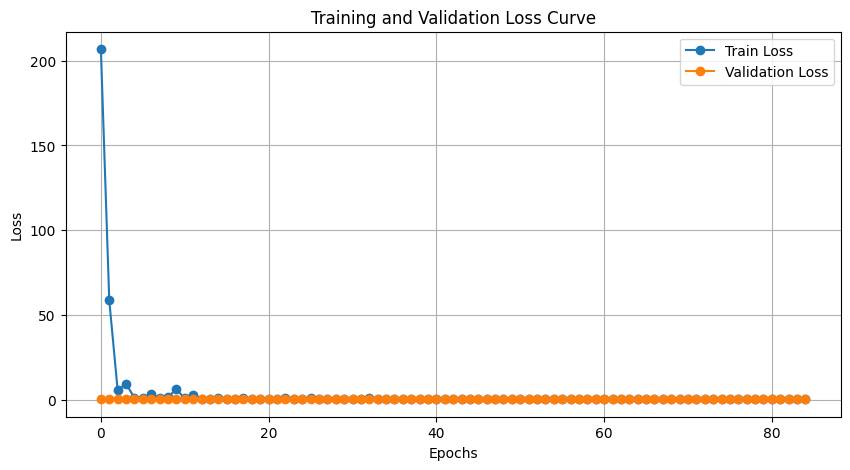

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


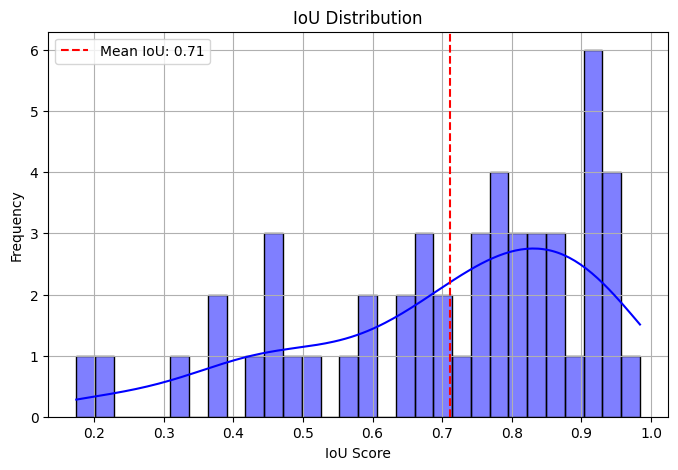

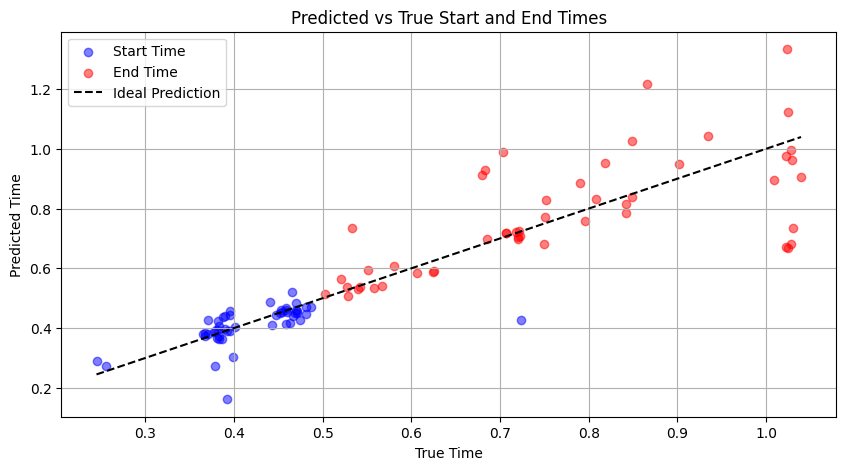

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


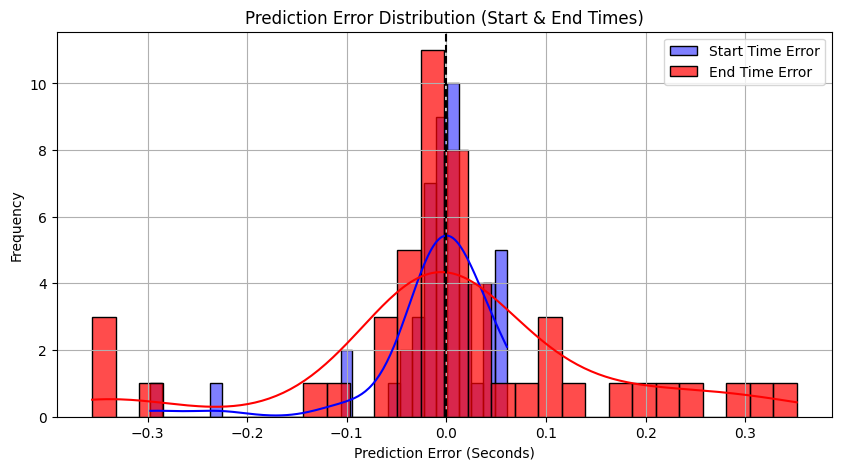

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1️⃣ **Loss Curve (Train vs Validation)**
plt.figure(figsize=(10,5))
plt.plot(train_losses, label="Train Loss", marker='o')
plt.plot(val_losses, label="Validation Loss", marker='o')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Curve")
plt.legend()
plt.grid()
plt.show()

# 2️⃣ **IoU Histogram**
plt.figure(figsize=(8,5))
sns.histplot(ious, bins=30, kde=True, color="blue")
plt.xlabel("IoU Score")
plt.ylabel("Frequency")
plt.title("IoU Distribution")
plt.axvline(mean_iou, color='red', linestyle="dashed", label=f"Mean IoU: {mean_iou:.2f}")
plt.legend()
plt.grid()
plt.show()

# 3️⃣ **Scatter Plot: Predicted vs True Start & End Times**
plt.figure(figsize=(10,5))
plt.scatter(y_test_orig[:,0], y_pred_tensor[:,0], label="Start Time", color="blue", alpha=0.5)
plt.scatter(y_test_orig[:,1], y_pred_tensor[:,1], label="End Time", color="red", alpha=0.5)
plt.plot([y_test_orig.min(), y_test_orig.max()], [y_test_orig.min(), y_test_orig.max()], 'k--', label="Ideal Prediction")
plt.xlabel("True Time")
plt.ylabel("Predicted Time")
plt.title("Predicted vs True Start and End Times")
plt.legend()
plt.grid()
plt.show()

# 4️⃣ **Error Distribution (Start & End Time)**
start_time_errors = y_pred_tensor[:,0] - y_test_orig[:,0]
end_time_errors = y_pred_tensor[:,1] - y_test_orig[:,1]

plt.figure(figsize=(10,5))
sns.histplot(start_time_errors, bins=30, kde=True, color="blue", label="Start Time Error")
sns.histplot(end_time_errors, bins=30, kde=True, color="red", label="End Time Error", alpha=0.7)
plt.xlabel("Prediction Error (Seconds)")
plt.ylabel("Frequency")
plt.title("Prediction Error Distribution (Start & End Times)")
plt.axvline(0, color='black', linestyle="dashed")
plt.legend()
plt.grid()
plt.show()


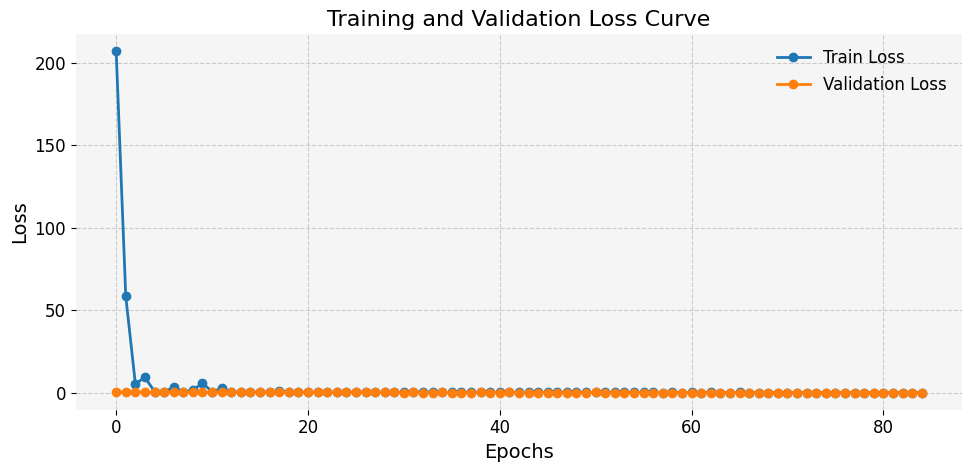

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


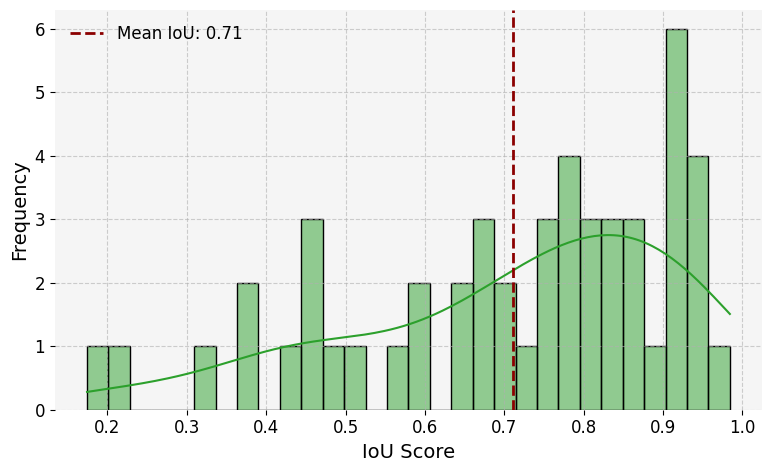

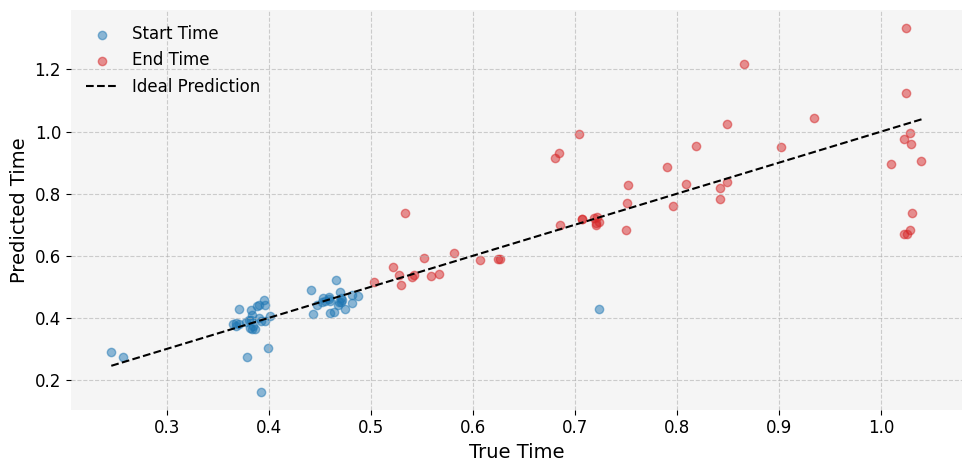

/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


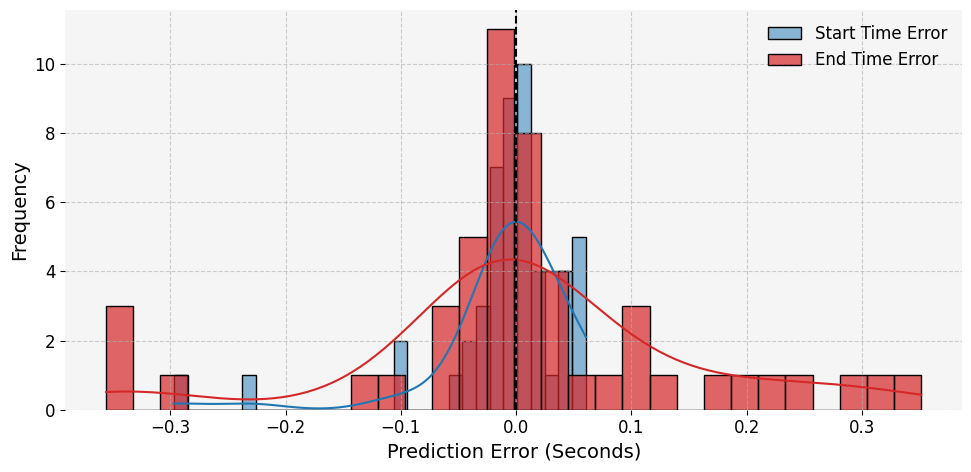

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set global font size for consistency
plt.rcParams.update({'font.size': 16})

# ==========================
# 1️⃣ Loss Curve (Train vs Validation)
# ==========================
fig_loss, ax_loss = plt.subplots(figsize=(10, 5))

ax_loss.plot(train_losses, label="Train Loss", marker='o', color='#1f77b4', linewidth=2)
ax_loss.plot(val_losses, label="Validation Loss", marker='o', color='#ff7f0e', linewidth=2)

ax_loss.set_xlabel("Epochs", fontsize=14)
ax_loss.set_ylabel("Loss", fontsize=14)
ax_loss.set_title("Training and Validation Loss Curve", fontsize=16)
ax_loss.legend(frameon=False, fontsize=12)
ax_loss.grid(True, linestyle='--', alpha=0.6)
ax_loss.set_facecolor('#f5f5f5')

for spine in ax_loss.spines.values():
    spine.set_visible(False)

ax_loss.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.savefig('loss_curve.png', dpi=300, bbox_inches='tight')
plt.show()

# ==========================
# 2️⃣ IoU Histogram
# ==========================
fig_iou, ax_iou = plt.subplots(figsize=(8, 5))

sns.histplot(ious, bins=30, kde=True, color='#2ca02c', ax=ax_iou)

ax_iou.set_xlabel("IoU Score", fontsize=14)
ax_iou.set_ylabel("Frequency", fontsize=14)
ax_iou.axvline(mean_iou, color='darkred', linestyle="dashed", linewidth=2, label=f"Mean IoU: {mean_iou:.2f}")

ax_iou.legend(frameon=False, fontsize=12)
ax_iou.grid(True, linestyle='--', alpha=0.6)
ax_iou.set_facecolor('#f5f5f5')

for spine in ax_iou.spines.values():
    spine.set_visible(False)

ax_iou.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.savefig('iou_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

# ==========================
# 3️⃣ Scatter Plot: Predicted vs True Start & End Times
# ==========================
fig_scatter, ax_scatter = plt.subplots(figsize=(10, 5))

ax_scatter.scatter(y_test_orig[:, 0], y_pred_tensor[:, 0], label="Start Time", color='#1f77b4', alpha=0.5)
ax_scatter.scatter(y_test_orig[:, 1], y_pred_tensor[:, 1], label="End Time", color='#d62728', alpha=0.5)

ax_scatter.plot([y_test_orig.min(), y_test_orig.max()],
                [y_test_orig.min(), y_test_orig.max()],
                'k--', label="Ideal Prediction", linewidth=1.5)

ax_scatter.set_xlabel("True Time", fontsize=14)
ax_scatter.set_ylabel("Predicted Time", fontsize=14)
# ax_scatter.set_title("Predicted vs True Start and End Times", fontsize=16)
ax_scatter.legend(frameon=False, fontsize=12)
ax_scatter.grid(True, linestyle='--', alpha=0.6)
ax_scatter.set_facecolor('#f5f5f5')

for spine in ax_scatter.spines.values():
    spine.set_visible(False)

ax_scatter.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.savefig('predicted_vs_true_times.png', dpi=300, bbox_inches='tight')
plt.show()

# ==========================
# 4️⃣ Error Distribution (Start & End Time)
# ==========================
start_time_errors = y_pred_tensor[:, 0] - y_test_orig[:, 0]
end_time_errors = y_pred_tensor[:, 1] - y_test_orig[:, 1]

fig_error, ax_error = plt.subplots(figsize=(10, 5))

sns.histplot(start_time_errors, bins=30, kde=True, color='#1f77b4', label="Start Time Error", ax=ax_error)
sns.histplot(end_time_errors, bins=30, kde=True, color='#d62728', label="End Time Error", ax=ax_error, alpha=0.7)

ax_error.set_xlabel("Prediction Error (Seconds)", fontsize=14)
ax_error.set_ylabel("Frequency", fontsize=14)

ax_error.axvline(0, color='black', linestyle="dashed", linewidth=1.5)

ax_error.legend(frameon=False, fontsize=12)
ax_error.grid(True, linestyle='--', alpha=0.6)
ax_error.set_facecolor('#f5f5f5')

for spine in ax_error.spines.values():
    spine.set_visible(False)

ax_error.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.savefig('error_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate MAE and RMSE for start and end times separately
mae_start = mean_absolute_error(y_test_orig[:, 0], y_pred_tensor[:, 0])
mae_end = mean_absolute_error(y_test_orig[:, 1], y_pred_tensor[:, 1])
rmse_start = np.sqrt(mean_squared_error(y_test_orig[:, 0], y_pred_tensor[:, 0]))
rmse_end = np.sqrt(mean_squared_error(y_test_orig[:, 1], y_pred_tensor[:, 1]))

print(f"MAE (start time): {mae_start:.4f}")
print(f"MAE (end time): {mae_end:.4f}")
print(f"RMSE (start time): {rmse_start:.4f}")
print(f"RMSE (end time): {rmse_end:.4f}")

MAE (start time): 0.0350
MAE (end time): 0.0950
RMSE (start time): 0.0631
RMSE (end time): 0.1458


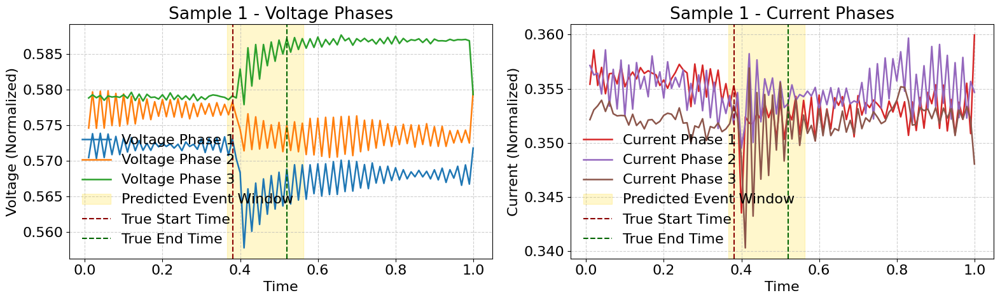

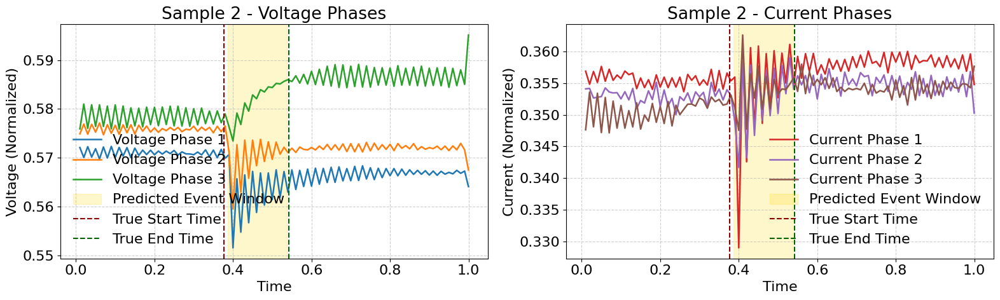

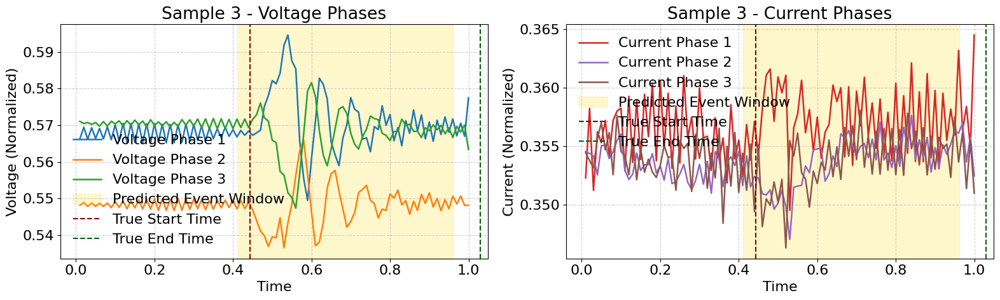

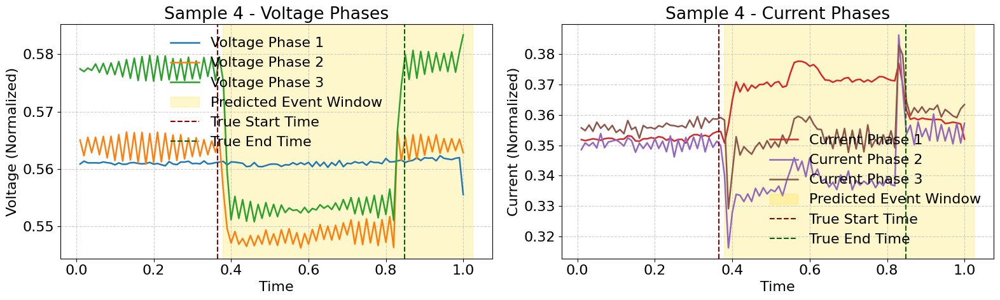

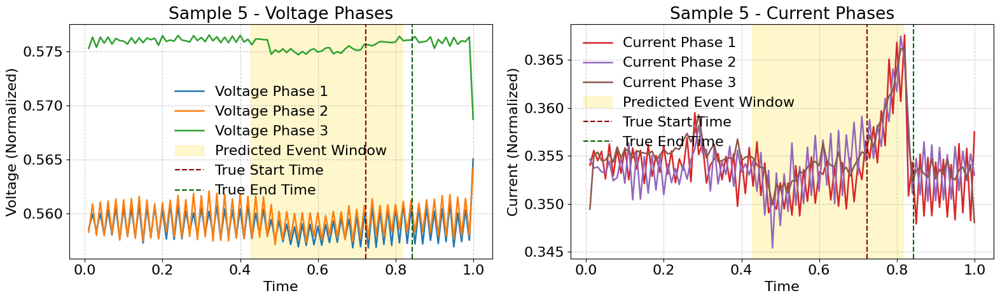

...

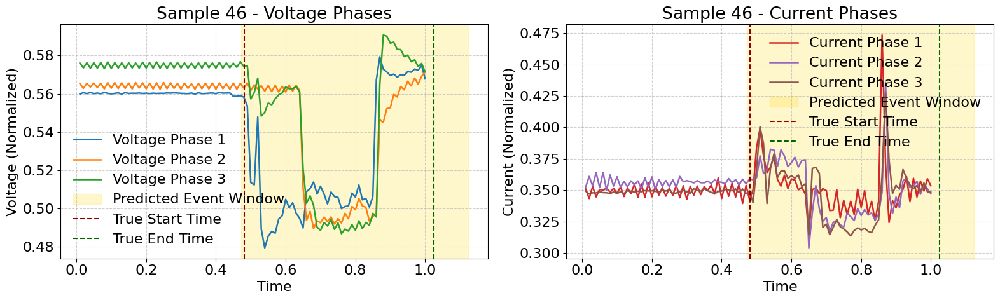

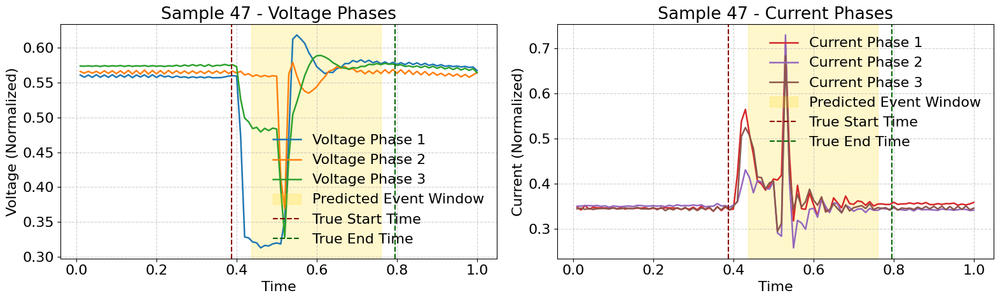

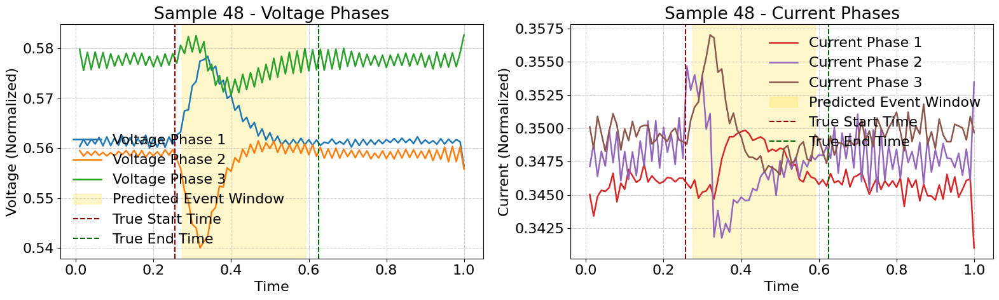

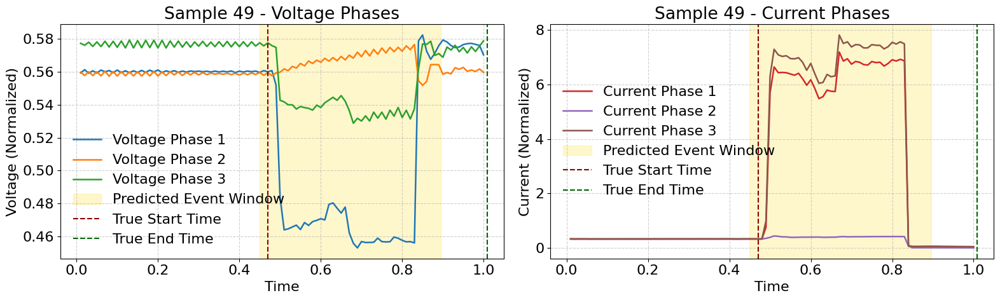

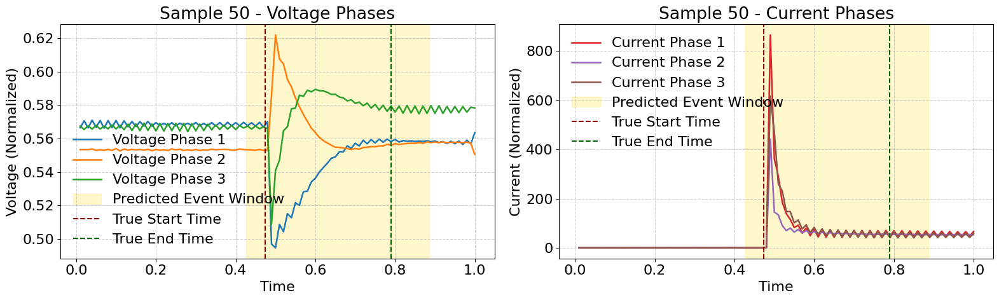

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Number of test samples to plot
num_samples = 50

# Define labels
voltage_labels = ['Voltage Phase 1', 'Voltage Phase 2', 'Voltage Phase 3']
current_labels = ['Current Phase 1', 'Current Phase 2', 'Current Phase 3']

# Define professional color palette (colorblind-friendly)
voltage_colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # blue, orange, green
current_colors = ['#d62728', '#9467bd', '#8c564b']  # red, purple, brown

# Loop through each test sample and plot
for test_sample in range(num_samples):
    # Extract data for the current test sample
    X_sample_1 = X_test_seq[test_sample]  # Shape: (time_steps, features)
    time_sample_1 = time_test_seq[test_sample]  # Shape: (time_steps,)

    # Get predicted and original start and end times
    pred_start_time = y_pred_tensor[test_sample][0]
    pred_end_time = y_pred_tensor[test_sample][1]
    orig_start_time = y_test_orig[test_sample][0]
    orig_end_time = y_test_orig[test_sample][1]

    # Create figure with 2 subplots side by side (no shared y-axis)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # ----- Voltage subplot -----
    ax_voltage = axes[0]
    for idx in range(3):  # Voltage Phases 1-3 (columns 0–2)
        ax_voltage.plot(time_sample_1, X_sample_1[:, idx],
                        label=voltage_labels[idx],
                        color=voltage_colors[idx],
                        linewidth=1.8)

    ax_voltage.axvspan(pred_start_time, pred_end_time, color='gold', alpha=0.2, label="Predicted Event Window")
    ax_voltage.axvline(orig_start_time, color='darkred', linestyle='dashed', linewidth=1.5, label="True Start Time")
    ax_voltage.axvline(orig_end_time, color='darkgreen', linestyle='dashed', linewidth=1.5, label="True End Time")

    ax_voltage.set_xlabel('Time')
    ax_voltage.set_ylabel('Voltage (Normalized)')
    ax_voltage.set_title(f'Sample {test_sample+1} - Voltage Phases')
    ax_voltage.legend(frameon=False)
    ax_voltage.grid(True, linestyle='--', alpha=0.6)

    # ----- Current subplot -----
    ax_current = axes[1]
    for idx in range(3, 6):  # Current Phases 1-3 (columns 3–5)
        ax_current.plot(time_sample_1, X_sample_1[:, idx],
                        label=current_labels[idx - 3],
                        color=current_colors[idx - 3],
                        linewidth=1.8)

    ax_current.axvspan(pred_start_time, pred_end_time, color='gold', alpha=0.2, label="Predicted Event Window")
    ax_current.axvline(orig_start_time, color='darkred', linestyle='dashed', linewidth=1.5, label="True Start Time")
    ax_current.axvline(orig_end_time, color='darkgreen', linestyle='dashed', linewidth=1.5, label="True End Time")

    ax_current.set_xlabel('Time')
    ax_current.set_ylabel('Current (Normalized)')
    ax_current.set_title(f'Sample {test_sample+1} - Current Phases')
    ax_current.legend(frameon=False)
    ax_current.grid(True, linestyle='--', alpha=0.6)

    # Optional: Add a main title
    # fig.suptitle(f'Test Sample {test_sample+1} - Voltage & Current Signals', fontsize=16)

    plt.tight_layout()
    plt.show()


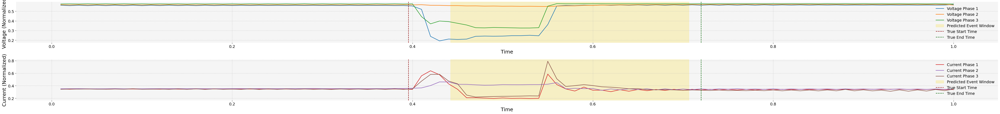

In [25]:
import matplotlib.pyplot as plt

# Define labels
voltage_labels = ['Voltage Phase 1', 'Voltage Phase 2', 'Voltage Phase 3']
current_labels = ['Current Phase 1', 'Current Phase 2', 'Current Phase 3']

# Define professional color palette (colorblind-friendly)
voltage_colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # blue, orange, green
current_colors = ['#d62728', '#9467bd', '#8c564b']  # red, purple, brown

# Choose Sample 44 (index 43)
test_sample = 43

# Extract data for Sample 44
X_sample_1 = X_test_seq[test_sample]
time_sample_1 = time_test_seq[test_sample]

# Get predicted and original start and end times
pred_start_time = y_pred_tensor[test_sample][0]
pred_end_time = y_pred_tensor[test_sample][1]
orig_start_time = y_test_orig[test_sample][0]
orig_end_time = y_test_orig[test_sample][1]

# Create figure with 2 subplots side by side (no shared y-axis)
fig, axes = plt.subplots(2, 1, figsize=(50, 6))

# Set global font sizes
plt.rcParams.update({'font.size': 16})  # Base font size

# ----- Voltage subplot -----
ax_voltage = axes[0]
for idx in range(3):
    ax_voltage.plot(time_sample_1, X_sample_1[:, idx],
                    label=voltage_labels[idx],
                    color=voltage_colors[idx],
                    linewidth=1.8)

# Add event annotations
ax_voltage.axvspan(pred_start_time, pred_end_time, color='gold', alpha=0.2, label="Predicted Event Window")
ax_voltage.axvline(orig_start_time, color='darkred', linestyle='dashed', linewidth=1.5, label="True Start Time")
ax_voltage.axvline(orig_end_time, color='darkgreen', linestyle='dashed', linewidth=1.5, label="True End Time")

# Labels and grid
ax_voltage.set_xlabel('Time', fontsize=18)
ax_voltage.set_ylabel('Voltage (Normalized)', fontsize=18)
ax_voltage.legend(frameon=False, fontsize=14)
ax_voltage.grid(True, linestyle='--', alpha=0.6)

# Set light gray background
ax_voltage.set_facecolor('#f5f5f5')  # Light gray

# Remove all spines (border)
for spine in ax_voltage.spines.values():
    spine.set_visible(False)

# Increase tick label size
ax_voltage.tick_params(axis='both', which='major', labelsize=14)

# ----- Current subplot -----
ax_current = axes[1]
for idx in range(3, 6):
    ax_current.plot(time_sample_1, X_sample_1[:, idx],
                    label=current_labels[idx - 3],
                    color=current_colors[idx - 3],
                    linewidth=1.8)

ax_current.axvspan(pred_start_time, pred_end_time, color='gold', alpha=0.2, label="Predicted Event Window")
ax_current.axvline(orig_start_time, color='darkred', linestyle='dashed', linewidth=1.5, label="True Start Time")
ax_current.axvline(orig_end_time, color='darkgreen', linestyle='dashed', linewidth=1.5, label="True End Time")

ax_current.set_xlabel('Time', fontsize=18)
ax_current.set_ylabel('Current (Normalized)', fontsize=18)
ax_current.legend(frameon=False, fontsize=14)
ax_current.grid(True, linestyle='--', alpha=0.6)

ax_current.set_facecolor('#f5f5f5')  # Light gray

for spine in ax_current.spines.values():
    spine.set_visible(False)

ax_current.tick_params(axis='both', which='major', labelsize=14)

# Final adjustments
plt.tight_layout()
plt.savefig('sample_44_voltage_current_plot.png', dpi=300, bbox_inches='tight')
plt.show()


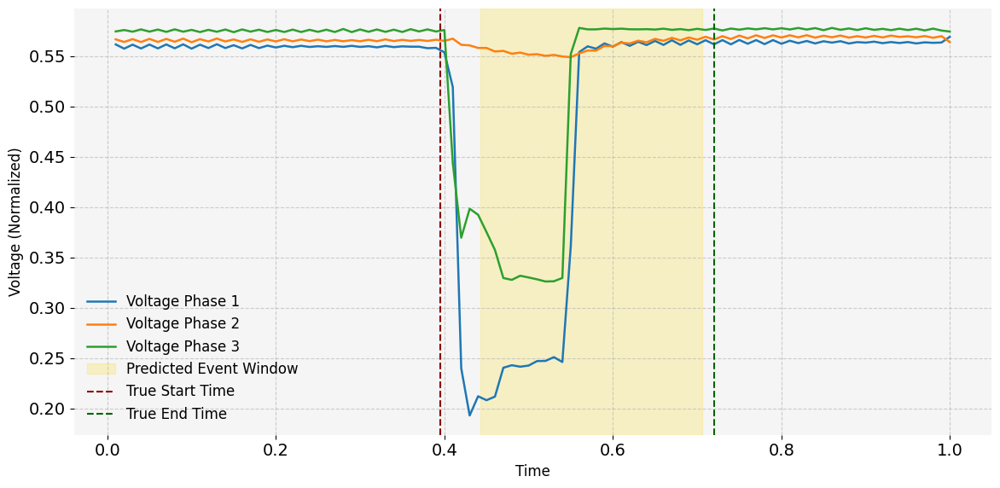

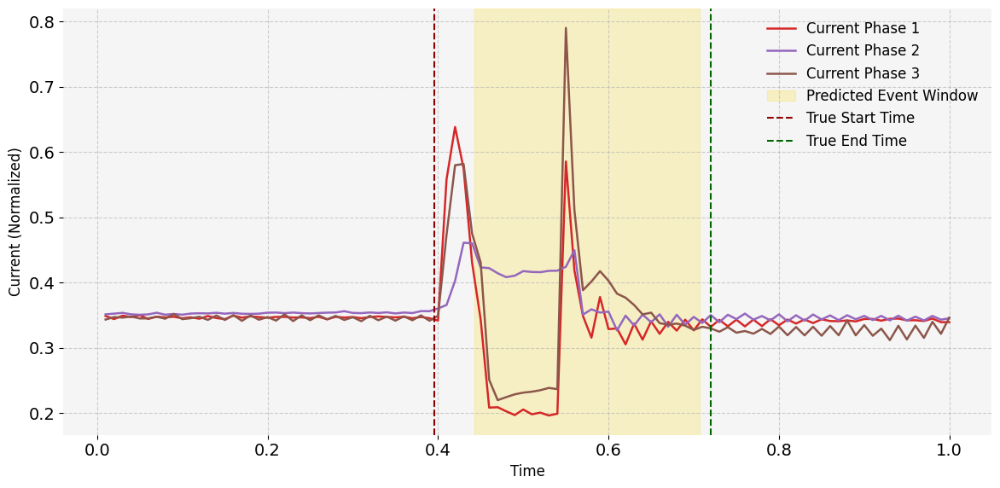

In [26]:
import matplotlib.pyplot as plt

# Define labels
voltage_labels = ['Voltage Phase 1', 'Voltage Phase 2', 'Voltage Phase 3']
current_labels = ['Current Phase 1', 'Current Phase 2', 'Current Phase 3']

# Define professional color palette (colorblind-friendly)
voltage_colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # blue, orange, green
current_colors = ['#d62728', '#9467bd', '#8c564b']  # red, purple, brown

# Choose Sample 44 (index 43)
test_sample = 43

# Extract data for Sample 44
X_sample_1 = X_test_seq[test_sample]
time_sample_1 = time_test_seq[test_sample]

# Get predicted and original start and end times
pred_start_time = y_pred_tensor[test_sample][0]
pred_end_time = y_pred_tensor[test_sample][1]
orig_start_time = y_test_orig[test_sample][0]
orig_end_time = y_test_orig[test_sample][1]

# ==========================
# First Plot: Voltage Phases
# ==========================

fig_v, ax_v = plt.subplots(figsize=(12, 6))

# Set global font sizes
plt.rcParams.update({'font.size': 16})

# Plot voltage phases
for idx in range(3):
    ax_v.plot(time_sample_1, X_sample_1[:, idx],
              label=voltage_labels[idx],
              color=voltage_colors[idx],
              linewidth=1.8)

# Add event annotations
ax_v.axvspan(pred_start_time, pred_end_time, color='gold', alpha=0.2, label="Predicted Event Window")
ax_v.axvline(orig_start_time, color='darkred', linestyle='dashed', linewidth=1.5, label="True Start Time")
ax_v.axvline(orig_end_time, color='darkgreen', linestyle='dashed', linewidth=1.5, label="True End Time")

# Labels and grid
ax_v.set_xlabel('Time', fontsize=12)
ax_v.set_ylabel('Voltage (Normalized)', fontsize=12)
ax_v.legend(frameon=False, fontsize=12)
ax_v.grid(True, linestyle='--', alpha=0.6)
ax_v.set_facecolor('#f5f5f5')

# Remove all spines
for spine in ax_v.spines.values():
    spine.set_visible(False)

ax_v.tick_params(axis='both', which='major', labelsize=14)

# Save voltage plot
plt.tight_layout()
plt.savefig('sample_44_voltage_plot.png', dpi=300, bbox_inches='tight')
plt.show()

# ==========================
# Second Plot: Current Phases
# ==========================

fig_c, ax_c = plt.subplots(figsize=(12, 6))

# Plot current phases
for idx in range(3, 6):
    ax_c.plot(time_sample_1, X_sample_1[:, idx],
              label=current_labels[idx - 3],
              color=current_colors[idx - 3],
              linewidth=1.8)

# Add event annotations
ax_c.axvspan(pred_start_time, pred_end_time, color='gold', alpha=0.2, label="Predicted Event Window")
ax_c.axvline(orig_start_time, color='darkred', linestyle='dashed', linewidth=1.5, label="True Start Time")
ax_c.axvline(orig_end_time, color='darkgreen', linestyle='dashed', linewidth=1.5, label="True End Time")

# Labels and grid
ax_c.set_xlabel('Time', fontsize=12)
ax_c.set_ylabel('Current (Normalized)', fontsize=12)
ax_c.legend(frameon=False, fontsize=12)
ax_c.grid(True, linestyle='--', alpha=0.6)
ax_c.set_facecolor('#f5f5f5')

# Remove all spines
for spine in ax_c.spines.values():
    spine.set_visible(False)

ax_c.tick_params(axis='both', which='major', labelsize=14)

# Save current plot
plt.tight_layout()
plt.savefig('sample_44_current_plot.png', dpi=300, bbox_inches='tight')
plt.show()
